<a id="title"></a>
# Level design and validation — Quantum Shield

This analysis documents **Flight Schools 1–6 and Main Levels 1–10** using the project's own configs, check validators, scorers and search. It is supporting analysis, not the team's final report. It was produced with project code and AI assistance; see [PROVENANCE.md](../PROVENANCE.md).

All displayed numbers and figures are computed by executed cells. Saved outputs are real Jupyter-kernel outputs, not a reconstruction of supposed earlier work. Execution metadata and cache generation times reflect actual runs; nothing is backdated.

From the repository root, create a separate analysis environment and run:

```powershell
python -m venv artifacts/notebook-env
artifacts/notebook-env/Scripts/python.exe -m pip install -r notebooks/requirements.txt
artifacts/notebook-env/Scripts/python.exe scripts/run_notebook.py
```

On Linux/macOS use `artifacts/notebook-env/bin/python`. Open this file in a Jupyter-capable editor to read the saved figures, or use nbconvert to export HTML. The runner uses a temporary kernel for its own interpreter, not whichever global kernel happens to be installed.

## Contents

0. [Purpose and running](#title)
1. [Setup, seeds and noise](#setup)
2. [Method recap](#method)
3. Flight Schools: [1](#fs1) · [2](#fs2) · [3](#fs3) · [4](#fs4) · [5](#fs5) · [6](#fs6)
4. Main missions: [1](#main1) · [2](#main2) · [3](#main3) · [4](#main4) · [5](#main5) · [6](#main6) · [7](#main7) · [8](#main8) · [9](#main9) · [10](#main10)
5. [Cross-level analysis](#cross-level)
6. [T-capable scorer validation](#t-validation)
7. [Reproducibility and machine-readable verification](#reproducibility)

<a id="setup"></a>
## 1. Setup, seeds and noise

The presentation helpers in `scripts/level_design_analysis.py` draw operation records and organize results; they do not implement propagation, noise evolution, postselection, decoding or search. Those functions are imported from the actual backend below. Seeds/shots come from stored tutorial references used by the regression suite.

The source-fingerprinted cache was generated by **running `backend.missions.reference.optimize`** for every main level. Only its expensive search is cached. All winning/baseline/blanket/reasonable drafts are run again here through the player engine. If physics or pinned simulation versions change, regenerate with `python scripts/cache_level_searches.py`; this does not change game levels or targets. Existing `scripts/validate_main_levels.py --optimize` independently reproduces the same finite-family search.

In [1]:
import os, sys, time, json, inspect, platform, warnings
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "backend/missions/levels.py").exists())
sys.path.insert(0, str(ROOT))
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"
START = time.perf_counter()
# Keep genuine warnings but omit machine-specific source-file paths.
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, JSON, Code
from qiskit.quantum_info import Pauli
from backend.quantum_core.pauli import opening_factor, propagate
from backend.quantum_core.checks import closing_factors
from backend.quantum_core.scoring import exact_density, ideal_reference, accepted_metrics
from backend.quantum_core.paulice import optimize_clifford
from backend.missions.simulation import execution_schedule, simulate
from backend.missions.reference import optimize
from scripts.cache_level_searches import load_searches
from scripts.run_notebook import analysis_inputs
from scripts import level_design_analysis as lab
from scripts.level_design_analysis import table
SEED, SHOTS = lab.SEED, lab.SHOTS
CACHE = load_searches()
SUMMARY, STRATEGY_ROWS = [], {}
plt.rcParams.update({"font.size":9, "figure.dpi":85})
table([dict(seed=SEED, shots=SHOTS, cachedSearchGeneratedUtc=CACHE["generatedAtUtc"],
            actualCacheSearchSeconds=CACHE["seconds"], generator=CACHE["generator"],
            physicsSourceFiles=len(CACHE["signature"]["files"]))])

seed,shots,cachedSearchGeneratedUtc,actualCacheSearchSeconds,generator,physicsSourceFiles
2026,1024,2026-10-16T11:43:12.654167+00:00,390.015,python scripts/cache_level_searches.py,56


In [2]:
from backend.timeline_lab.service import HOTSPOT, CHECK_STRENGTH
from backend.timeline_lab.capstone_examples import example
from backend.missions.levels import get_level
from backend.quantum_core.noise import hardware_items
noise_rows = [dict(workload="FS2 hardware reference", parameters=lab.TUTORIALS[1]["experiment"]["hardware"]),
              dict(workload="FS6 hardware + hotspot + check cost", parameters={
                  "hardware": example().hardware.model_dump(), "hotspot": HOTSPOT, "checkStrength":CHECK_STRENGTH})]
noise_rows += [dict(workload=f"Main {i}", parameters=get_level(i)["noise"]) for i in (1,10)]
table(noise_rows)
print("Synthetic teaching channels, not backend calibration. Independent channels compose after occupied layers, including check/T gates.")
print("The generator/validator keep Paulice's native gate-noise cost separate from the game noise protocols.")

workload,parameters
FS2 hardware reference,"{""enabled"": true, ""bitFlip"": 0.025, ""phaseFlip"": 0.01, ""depolarizing"": 0, ""relaxationTimeUs"": 0, ""t1Us"": 100, ""t2Us"": 80}"
FS6 hardware + hotspot + check cost,"{""hardware"": {""enabled"": true, ""bitFlip"": 0.001, ""phaseFlip"": 0.001, ""depolarizing"": 0, ""relaxationTimeUs"": 0, ""t1Us"": 100, ""t2Us"": 80}, ""hotspot"": {""channel"": ""decoherence"", ""timeUs"": 70.0, ""t1Us"": 100.0, ""t2Us"": 200.0}, ""checkStrength"": 0.02}"
Main 1,"{""hotspotColumn"": 1, ""qubit"": 1, ""timeUs"": 76.0, ""t1Us"": 100.0, ""t2Us"": 200.0, ""checkStrength"": 0.025, ""hardware"": {""enabled"": true, ""bitFlip"": 0.00015, ""phaseFlip"": 0.00015, ""depolarizing"": 0.0002, ""relaxationTimeUs"": 0.0, ""t1Us"": 100.0, ""t2Us"": 200.0}}"
Main 10,"{""hotspotColumn"": 5, ""qubit"": 1, ""timeUs"": 94.0, ""t1Us"": 100.0, ""t2Us"": 200.0, ""checkStrength"": 0.025, ""hardware"": {""enabled"": true, ""bitFlip"": 0.00015, ""phaseFlip"": 0.00015, ""depolarizing"": 0.0002, ""relaxationTimeUs"": 0.0, ""t1Us"": 100.0, ""t2Us"": 200.0}}"


Synthetic teaching channels, not backend calibration. Independent channels compose after occupied layers, including check/T gates.
The generator/validator keep Paulice's native gate-noise cost separate from the game noise protocols.


<a id="method"></a>
## 2. Method recap

An ancilla H, controlled opening P, payload interval U, controlled inverse closing P′, H and measurement form the check. The ideal relation is P′U=UP; signed/ordered products require phase compensation. The real validator checks the full input isometry, not just one input state. Dynamic window selection and generated closings stay in the real mission service.

Cliffords transport a Pauli to one signed Pauli. T/Tdg reject X/Y support at a crossing; I/Z commute. The noisy scorer for **all** missions is exact Aer density-matrix evolution; the ideal projector uses stabilizers for Clifford payloads and a statevector for T payloads. For the all-zero-syndrome block B: kept yield is Tr(B), postselected fidelity is Tr(rho_ideal B)/Tr(B), and combined score is their product. No finite-shot fluctuation decides a pass.

In [3]:
demo=[]
for gate, axis in [("h","X"),("s","X"),("sdg","X"),("t","Z"),("t","X"),("tdg","Y")]:
    try:
        frame=propagate(opening_factor(1,0,axis),gate,[0],1)
        demo.append(dict(gate=gate, opening=axis, transported=frame.to_label(), status="single Pauli"))
    except ValueError as error:
        demo.append(dict(gate=gate, opening=axis, transported=None, status=str(error)))
table(demo)
frame=propagate(opening_factor(1,0,"X"),"sdg",[0],1)
print("Actual inverse-closing factors, including relative phase:",closing_factors(frame.to_matrix(),1))
level=get_level(1)
draft=lab.MissionDraft.model_validate(lab.REFERENCES["levels"][0]["reasonableDraft"])
checked=lab.missions.validate(draft)
metrics=simulate(level,checked["operations"])
table([dict(valid=checked["valid"], **metrics)])
assert abs(metrics["score"]-metrics["fidelity"]*metrics["retention"])<1e-12

gate,opening,transported,status
h,X,Z,single Pauli
s,X,Y,single Pauli
sdg,X,-Y,single Pauli
t,Z,Z,single Pauli
t,X,—,Non-Pauli transport: use only Z/I at a T or Tdg crossing.
tdg,Y,—,Non-Pauli transport: use only Z/I at a T or Tdg crossing.


Actual inverse-closing factors, including relative phase: [('cy', [1, 0]), ('z', [1])]


valid,fidelity,retention,score
True,0.827334,0.823588,0.681383


Targets were calibrated by the existing script and are not re-tuned in this notebook. The exact source excerpt below documents the main-level interpolation/rounding and safety assertions; FS6 uses the target returned by its own evaluator. “Optimal” throughout means **best in the declared finite search family**, not a global optimum over arbitrary multi-helper circuits. Native Paulice gamma suggestions are a different objective and are never used as T-level scores or optima.

In [4]:
from scripts.validate_main_levels import calibrate
lines=inspect.getsource(calibrate).splitlines()
selected=[line for line in lines if any(word in line for word in ("target=", "assert max(baseline", "baseline=_run", "o=best"))]
display(Code("\n".join(selected),language="python"))

unchecked=empty(number); baseline=_run(unchecked.model_dump_json())['combinedScore']
        o=best['best']['score']
        target=math.floor((baseline+(.65+.013*number)*(o-baseline))*100)/100
        assert max(baseline,e)+.005<target<r-.005<o, (number,baseline,e,r,o,target)
                 baseline=baseline,everywhere=e,reasonable=r,optimal=o,target=target,spread=0.,
        rows.append(row);print(f'{number}: baseline={baseline:.6f} everywhere={e:.6f} reasonable={r:.6f} optimum={o:.6f} target={target:.2f}',flush=True)

<a id="fs1"></a>
## 3.1. Flight School 1 — Quantum errors

The stored X-error reference and additional allowed phase/decoherence experiments use the actual FS1 run function. The extra waiting times are experimental inputs, not authored changes to a level. Compare exact probabilities with seeded counts; phase-flipped plus/minus states can agree in Z but disagree in X. This lesson completes by experiment and MCQs, not a score threshold.

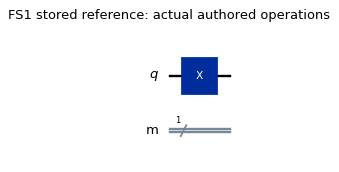

experiment,basis,fidelity,idealProbabilities,noisyProbabilities,counts
stored X error,Z,0,"{""0"": 1.0, ""1"": 0.0}","{""0"": 0.0, ""1"": 1.0}","{""0"": 0, ""1"": 1024}"
Z error on plus / Z readout,Z,3.14018e-16,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 474, ""1"": 550}"
Z error on plus / X readout,X,3.14018e-16,"{""0"": 0.9999999999999997, ""1"": 0.0}","{""0"": 0.0, ""1"": 0.9999999999999997}","{""0"": 0, ""1"": 1024}"
"wait 0 us (T1=100, T2=80)",Z,1,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 474, ""1"": 550}"
"wait 20 us (T1=100, T2=80)",Z,0.8894,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.5906346234610089, ""1"": 0.4093653765389908}","{""0"": 573, ""1"": 451}"
"wait 60 us (T1=100, T2=80)",Z,0.736183,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.7255941819529865, ""1"": 0.2744058180470132}","{""0"": 718, ""1"": 306}"
"wait 120 us (T1=100, T2=80)",Z,0.611565,"{""0"": 0.4999999999999999, ""1"": 0.4999999999999999}","{""0"": 0.8494028940438987, ""1"": 0.15059710595610107}","{""0"": 858, ""1"": 166}"


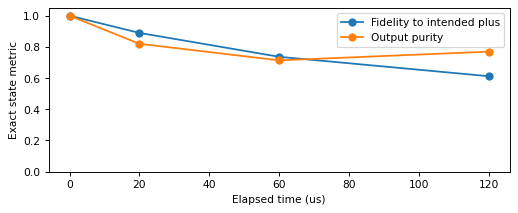

In [5]:
SUMMARY.append(lab.noise_school())

<a id="fs2"></a>
## 3.2. Flight School 2 — Detection, mitigation and correction

Run the same stored hardware-noise experiment with noise enabled/disabled for each method. Detection returns a filtered state, mitigation an observable estimate (not a state), and correction a decoded state. The circuit pictures show the actual generated gate/readout/recovery structure; background noise channels are omitted only in drawings. Added noisy gates can make a method worse. Completion requires trying all methods, not maximizing an invented fidelity target.

hardware,method,idealE,noisyE,finalE,sampledE,stateFidelity,kept,physicalQubits,methodShots
False,detection,1,1,1,1,1,1,2,1024
False,mitigation,1,1,1,1,—,—,1,3072
False,correction,1,1,1,1,1,1,5,1024
True,detection,1,0.95,0.851598,0.848018,0.925799,0.895408,2,1024
True,mitigation,1,0.95,0.99255,0.98763,—,—,1,3072
True,correction,1,0.95,0.438409,0.439453,0.719204,1,5,1024


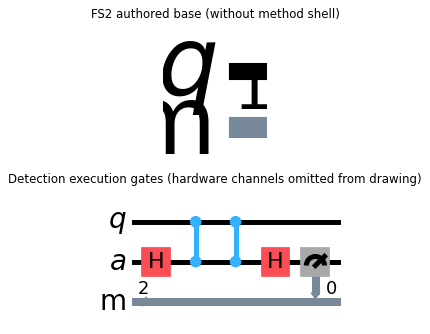

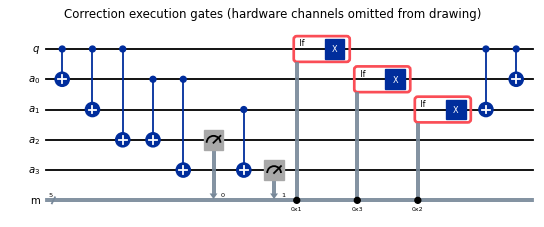

hardware,completion,interpretation
"{""enabled"": true, ""bitFlip"": 0.025, ""phaseFlip"": 0.01, ""depolarizing"": 0, ""relaxationTimeUs"": 0, ""t1Us"": 100, ""t2Us"": 80}",Try all three methods on a valid authored circuit.,"Mitigation estimates E, not a repaired quantum state; compare E, not fabricated mitigation state fidelity."


In [6]:
SUMMARY.append(lab.protection_school())

<a id="fs3"></a>
## 3.3. Flight School 3 — Coherent Pauli checks across S

The guided S payload transports the stored opening through the shared core step by step. The full validator certifies the reference; a changed closing gate is invalid. The stored injected fault and a fault-free variant demonstrate that a green ideal identity can still flag real noise. Completion also needs the existing knowledge check.

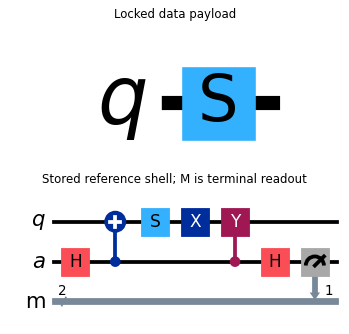

step,operator,status
Opening,X,Pauli
S[0],Y,Pauli


case,valid,connector,nonPauli,syndromeCounts,explanation
stored reference,True,GREEN,False,"{""1"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
without explicit fault,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
incorrect CX check,False,RED,False,—,Closing product or sign does not match U P U†.


In [7]:
SUMMARY.append(lab.check_school(3))

<a id="fs4"></a>
## 3.4. Flight School 4 — Multi-qubit CNOT propagation

The actual guided H/CX payload transports the stored opening into a product check. Removing a closing factor gives the contrasting invalid result. A multi-wire match must preserve the complete noiseless input isometry; circuit pictures are drawn by Qiskit. Completion also requires the lesson knowledge answers.

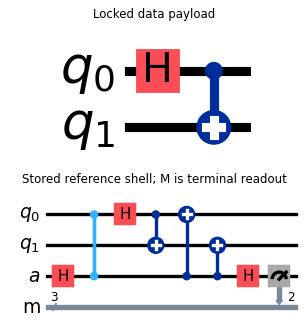

step,operator,status
Opening,IZ,Pauli
H[0],IX,Pauli
"CX[0, 1]",XX,Pauli


case,valid,connector,nonPauli,syndromeCounts,explanation
stored reference,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
without explicit fault,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
incomplete single-wire closing,False,RED,False,—,Closing product or sign does not match U P U†.


In [8]:
SUMMARY.append(lab.check_school(4))

<a id="fs5"></a>
## 3.5. Flight School 5 — The non-Clifford barrier

The guided T payload accepts the stored Z shell. X/Y versions are rejected by the real validator before scoring; core propagation explains where a single Pauli is lost. The table is a physical validity test, not an arbitrary gameplay penalty. Completion uses the valid experiment plus its knowledge answer.

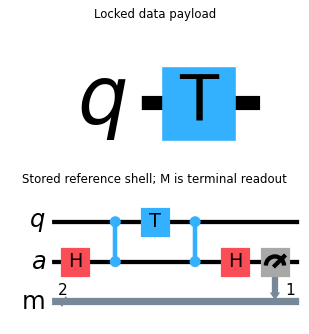

step,operator,status
Opening,Z,Pauli
T[0],Z,Pauli


case,valid,connector,nonPauli,syndromeCounts,explanation
stored reference,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
without explicit fault,True,GREEN,False,"{""0"": 1024}",Closed operator identity and complete H / CP / CP / H / M shell.
incorrect CX check,False,RED,True,—,Non-Pauli transport at T: the check becomes a coherent Pauli sum; a Pauli-only closure is unsupported.
incorrect CY check,False,RED,True,—,Non-Pauli transport at T: the check becomes a coherent Pauli sum; a Pauli-only closure is unsupported.


step,operator,status
Opening,X,Pauli
T[0],—,Non-Pauli transport: use only Z/I at a T or Tdg crossing.
Opening,Y,Pauli
T[0],—,Non-Pauli transport: use only Z/I at a T or Tdg crossing.


In [9]:
SUMMARY.append(lab.check_school(5))

<a id="fs6"></a>
## 3.6. Flight School 6 — Trade-off optimization

The fixed short Clifford payload has two data qubits, one helper and a localized relaxation hotspot. Baseline, blanket, sensible and bounded-best drafts are evaluated repeatedly with the same hardware settings. The target must lie above careless strategies and below a sensible solution. The real native Paulice suggestion is shown separately from the independently enumerated game-score reference.

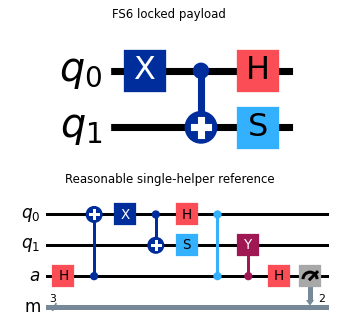

strategy,fidelity,kept,score,target,spread,valid
baseline,0.494132,1,0.494132,0.62,0,False
everywhere,0.478589,0.954849,0.45698,0.62,0,True
reasonable,0.816186,0.818607,0.668136,0.62,0,True
optimal,0.827609,0.829038,0.686119,0.62,0,True


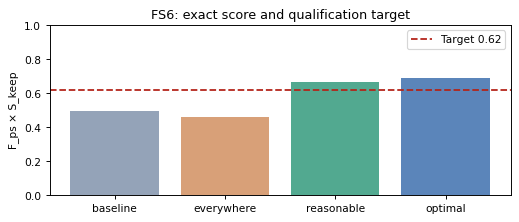

Game reference search: Exact maximum over 15 single-ancilla full-payload Pauli-product shells; fixed tap order and terminal readout. Arbitrary placements and multi-check circuits are outside this certificate. Candidates: 15
Separate native Paulice gamma: 1.0202354230673039 added helpers: 0


In [10]:
SUMMARY.append(lab.capstone())

<a id="main1"></a>
## 4.1. Main Level 1

Manual opening/closing on two data wires and one helper. The reasonable reference uses an inserted interior interval; the drawing labels the editable bands instead of pretending the payload itself is editable.

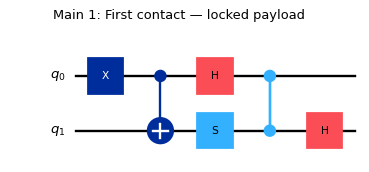

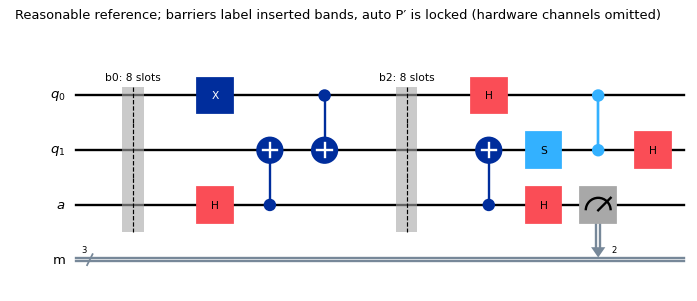

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.466665,1,0.466665,0.6,0,False,False,0,0
everywhere,0.454601,0.958589,0.435775,0.6,0,True,False,1,3
reasonable,0.827334,0.823588,0.681383,0.6,0,True,True,1,2
optimal,0.827453,0.82375,0.681615,0.6,0,True,True,1,2


Data: 2 Fixed helpers: 1 T/Tdg: 0 Payload gates: 6 Depth: 5
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 1, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 76.0}
Inserted editable bands: {"0": 8, "2": 8, "6": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b0s2", "closing": "b2s1", "valid": true}]
Separate native Paulice gamma: 1.037410717419716 added helpers: 1
Search: clifford-pauli-reference-search candidates: 75 best opening: XI interval: (1, 2) cached search seconds: 2.514
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


In [11]:
row, STRATEGY_ROWS[1] = lab.main_level(1, CACHE)
SUMMARY.append(row)

<a id="main2"></a>
## 4.2. Main Level 2

A wider Clifford payload with a single helper tests manual product closure and careful window selection. All reference drafts are the same player-reachable records used by validation.

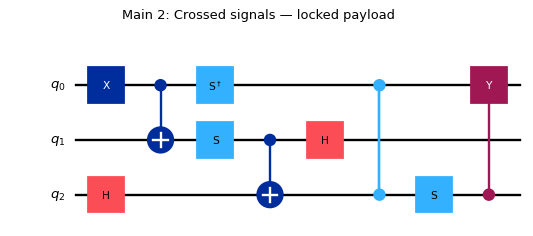

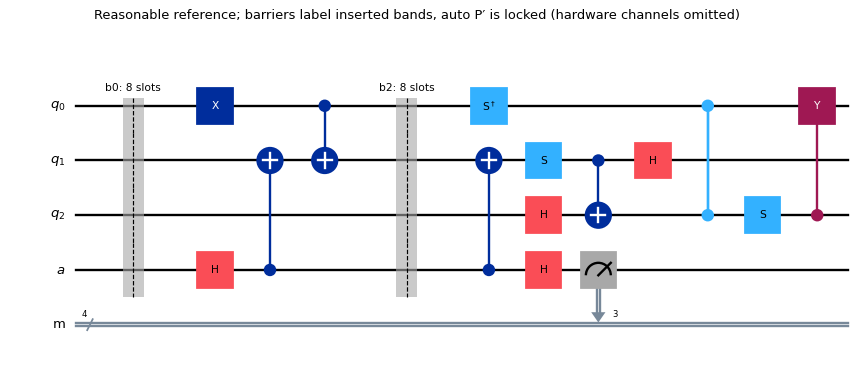

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.455944,1,0.455944,0.6,0,False,False,0,0
everywhere,0.437008,0.92924,0.406086,0.6,0,True,False,1,5
reasonable,0.819311,0.820369,0.672137,0.6,0,True,True,1,2
optimal,0.819429,0.820529,0.672365,0.6,0,True,True,1,2


Data: 3 Fixed helpers: 1 T/Tdg: 0 Payload gates: 10 Depth: 7
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 1, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 78.0}
Inserted editable bands: {"0": 8, "10": 8, "2": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b0s2", "closing": "b2s1", "valid": true}]
Separate native Paulice gamma: 1.0584031621812593 added helpers: 1
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (1, 2) cached search seconds: 15.495
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


In [12]:
row, STRATEGY_ROWS[2] = lab.main_level(2, CACHE)
SUMMARY.append(row)

<a id="main3"></a>
## 4.3. Main Level 3

Manual signed closures with a larger helper budget test support spreading and overlapping-check costs. Blanket checks are valid comparison circuits, but their resource/noise overhead can lose.

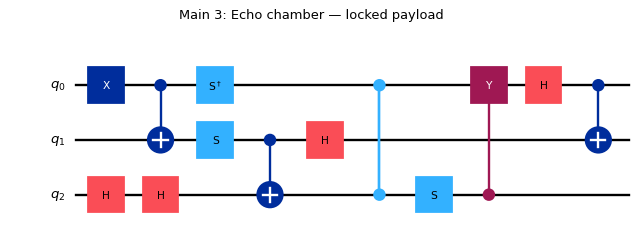

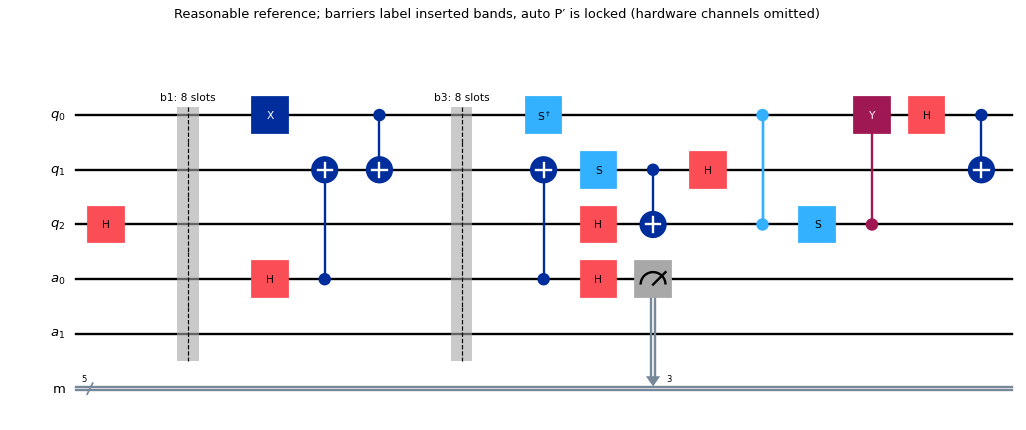

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.445385,1,0.445385,0.59,0,False,False,0,0
everywhere,0.412004,0.815689,0.336067,0.59,0,True,False,2,12
reasonable,0.814416,0.817022,0.665396,0.59,0,True,True,1,2
optimal,0.814533,0.817181,0.665621,0.59,0,True,True,1,2


Data: 3 Fixed helpers: 2 T/Tdg: 0 Payload gates: 13 Depth: 9
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 2, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 80.0}
Inserted editable bands: {"0": 4, "1": 8, "13": 8, "3": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b1s2", "closing": "b3s1", "valid": true}]
Separate native Paulice gamma: 1.07622099661729 added helpers: 2
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (2, 3) cached search seconds: 15.981
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


In [13]:
row, STRATEGY_ROWS[3] = lab.main_level(3, CACHE)
SUMMARY.append(row)

<a id="main4"></a>
## 4.4. Main Level 4

Assisted P′ is generated by the real validator on the selected interior interval. Generated gates are labeled in the Qiskit image and listed as locked operations below.

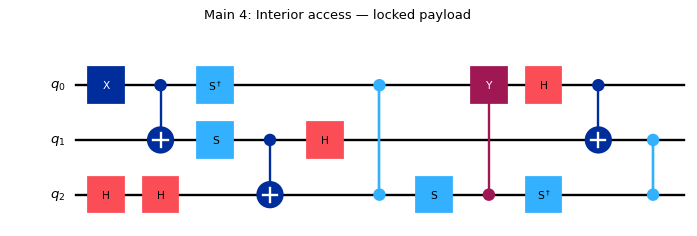

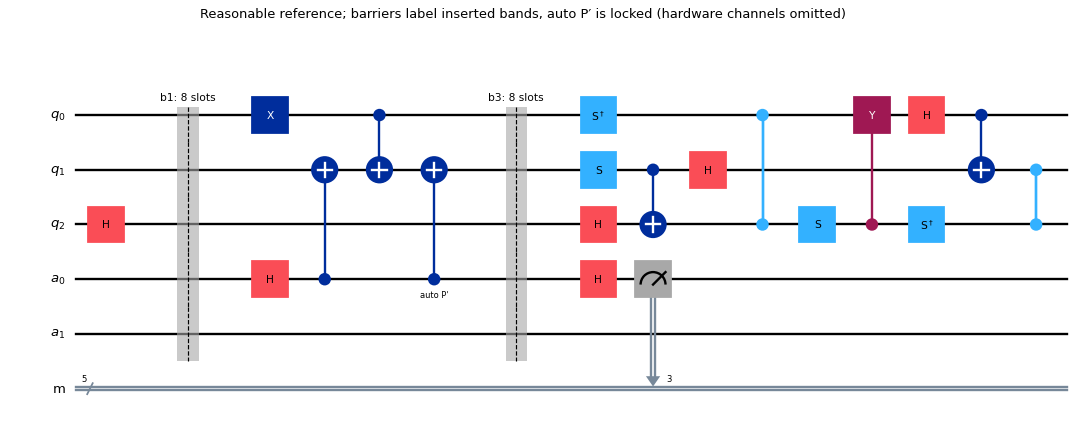

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.436066,1,0.436066,0.59,0,False,False,0,0
everywhere,0.407866,0.813798,0.331921,0.59,0,True,False,2,12
reasonable,0.810022,0.813868,0.659251,0.59,0,True,True,1,2
optimal,0.810138,0.814025,0.659472,0.59,0,True,True,1,2


Data: 3 Fixed helpers: 2 T/Tdg: 0 Payload gates: 15 Depth: 10
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 2, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 82.0}
Inserted editable bands: {"0": 4, "1": 8, "15": 8, "3": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b1s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [3, 1], "location": "auto-0-0", "locked": true}]
Separate native Paulice gamma: 1.0979987837977563 added helpers: 2
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (2, 3) cached search seconds: 17.227
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


In [14]:
row, STRATEGY_ROWS[4] = lab.main_level(4, CACHE)
SUMMARY.append(row)

<a id="main5"></a>
## 4.5. Main Level 5

A longer Clifford path spreads the transported support. The assisted closer is recomputed from the authored opening and actual interval; no notebook-specific closing rule is supplied.

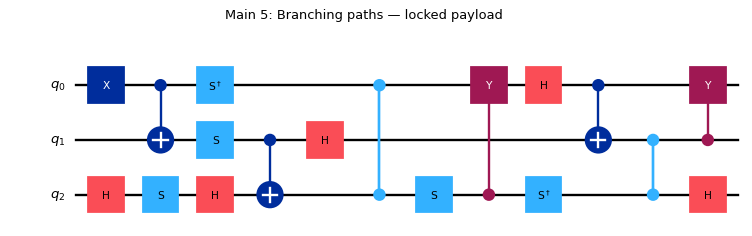

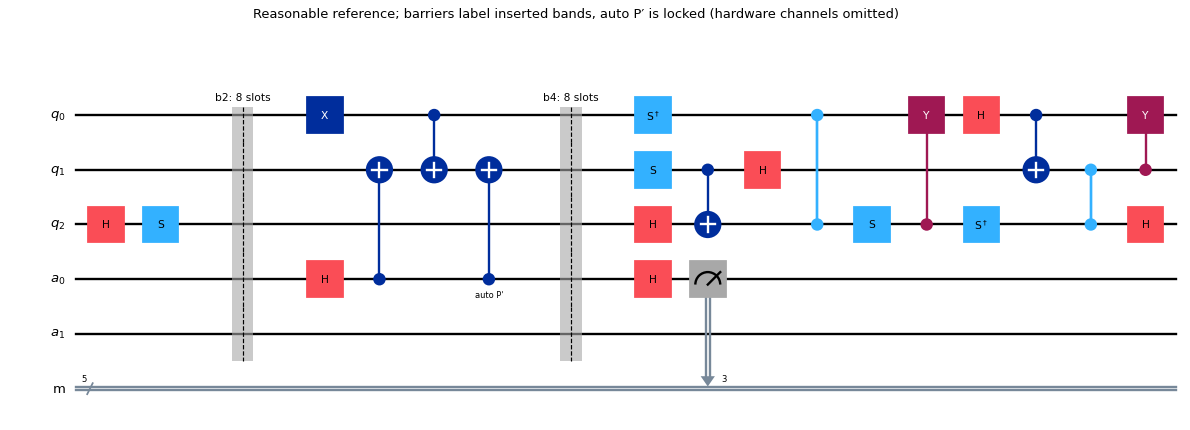

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.424433,1,0.424433,0.58,0,False,False,0,0
everywhere,0.392453,0.810364,0.31803,0.58,0,True,False,2,12
reasonable,0.80075,0.810589,0.649079,0.58,0,True,True,1,2
optimal,0.800864,0.810745,0.649297,0.58,0,True,True,1,2


Data: 3 Fixed helpers: 2 T/Tdg: 0 Payload gates: 18 Depth: 11
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 3, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 84.0}
Inserted editable bands: {"0": 4, "18": 8, "2": 8, "4": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b2s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [3, 1], "location": "auto-0-0", "locked": true}]
Separate native Paulice gamma: 1.0744257977084226 added helpers: 2
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (3, 4) cached search seconds: 21.154
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


In [15]:
row, STRATEGY_ROWS[5] = lab.main_level(5, CACHE)
SUMMARY.append(row)

<a id="main6"></a>
## 4.6. Main Level 6

The larger Clifford workload adds noisy opportunities without changing the score definition. Compare the reasonable interval with a blanket strategy and the cached finite-family winner.

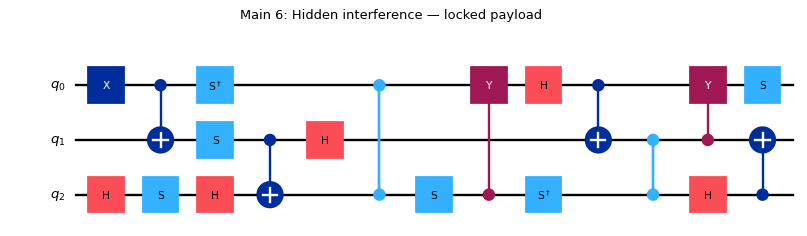

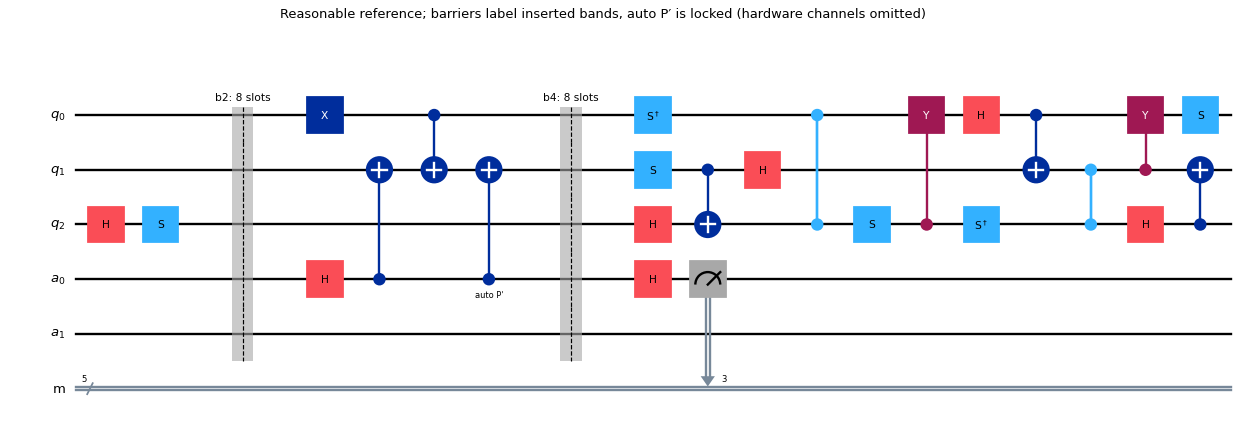

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.414982,1,0.414982,0.58,0,False,False,0,0
everywhere,0.385864,0.833232,0.321514,0.58,0,True,False,2,10
reasonable,0.795526,0.807499,0.642386,0.58,0,True,True,1,2
optimal,0.795639,0.807653,0.6426,0.58,0,True,True,1,2


Data: 3 Fixed helpers: 2 T/Tdg: 0 Payload gates: 20 Depth: 12
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 3, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 86.0}
Inserted editable bands: {"0": 4, "2": 8, "20": 8, "4": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b2s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [3, 1], "location": "auto-0-0", "locked": true}]
Separate native Paulice gamma: 1.0780191950251732 added helpers: 2
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (3, 4) cached search seconds: 21.487
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


In [16]:
row, STRATEGY_ROWS[6] = lab.main_level(6, CACHE)
SUMMARY.append(row)

<a id="main7"></a>
## 4.7. Main Level 7

The largest Clifford mission permits more helpers. The full-isometry validator must accept simultaneous loops; native Paulice gamma remains distinct from the exact game-score search.

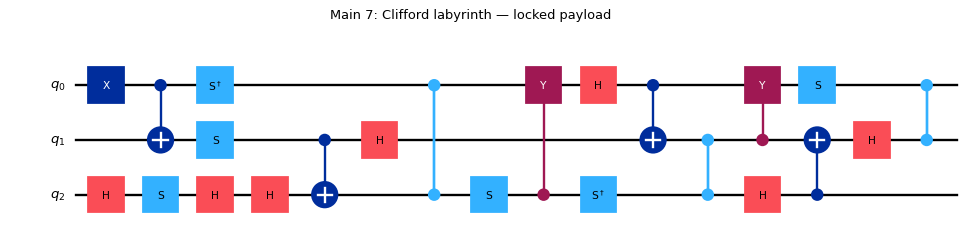

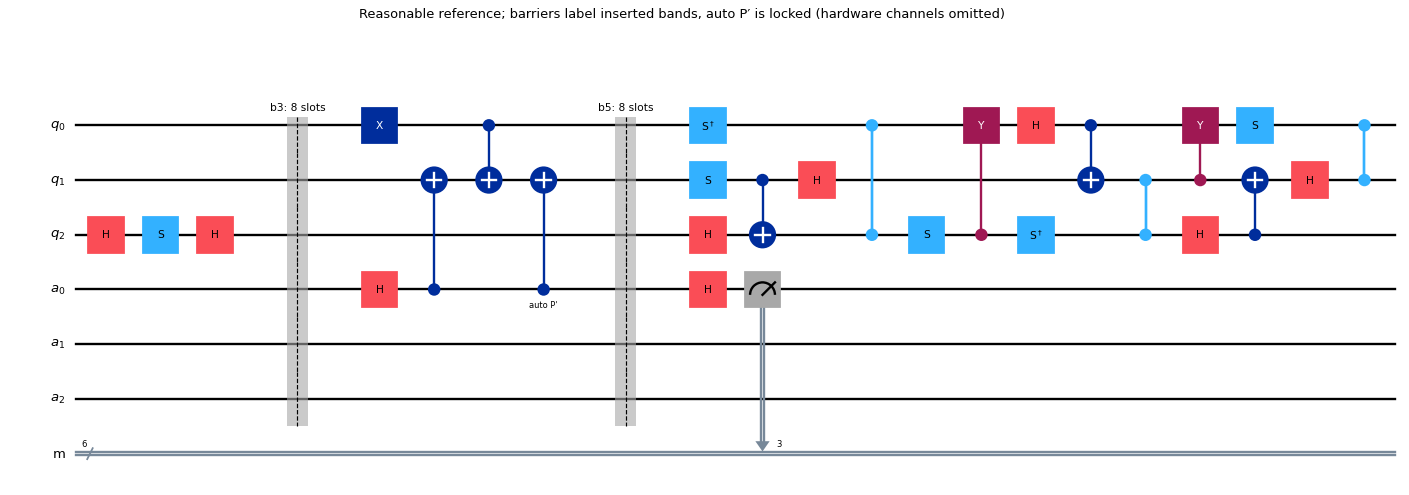

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.405382,1,0.405382,0.57,0,False,False,0,0
everywhere,0.3668,0.752976,0.276192,0.57,0,True,False,3,15
reasonable,0.789661,0.804287,0.635114,0.57,0,True,True,1,2
optimal,0.789774,0.804439,0.635325,0.57,0,True,True,1,2


Data: 3 Fixed helpers: 3 T/Tdg: 0 Payload gates: 23 Depth: 15
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 4, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 88.0}
Inserted editable bands: {"0": 4, "23": 8, "3": 8, "5": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b3s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [3, 1], "location": "auto-0-0", "locked": true}]
Separate native Paulice gamma: 1.0637173141310472 added helpers: 3
Search: clifford-pauli-reference-search candidates: 315 best opening: IXI interval: (4, 5) cached search seconds: 24.376
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; stabilizer ideal


In [17]:
row, STRATEGY_ROWS[7] = lab.main_level(7, CACHE)
SUMMARY.append(row)

<a id="main8"></a>
## 4.8. Main Level 8

The first T-doped payload uses an exact Aer density scorer with a statevector ideal. The cached custom search comes from the real optimizer, accepts only I/Z support at T crossings, and its winning draft is freshly rescored here. Paulice is not called on this circuit.

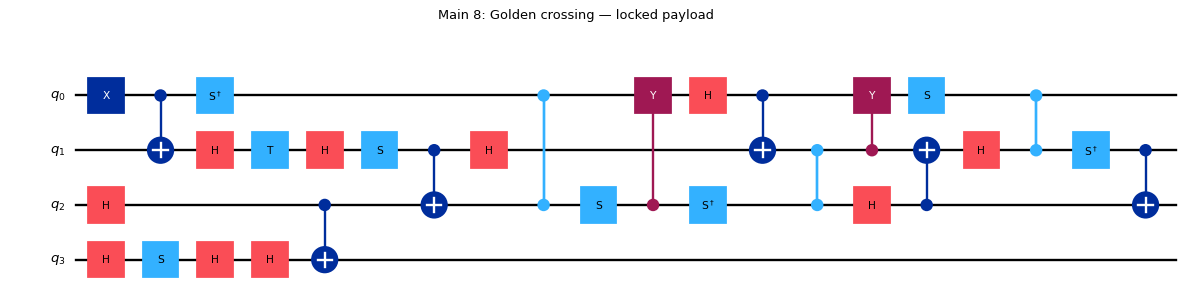

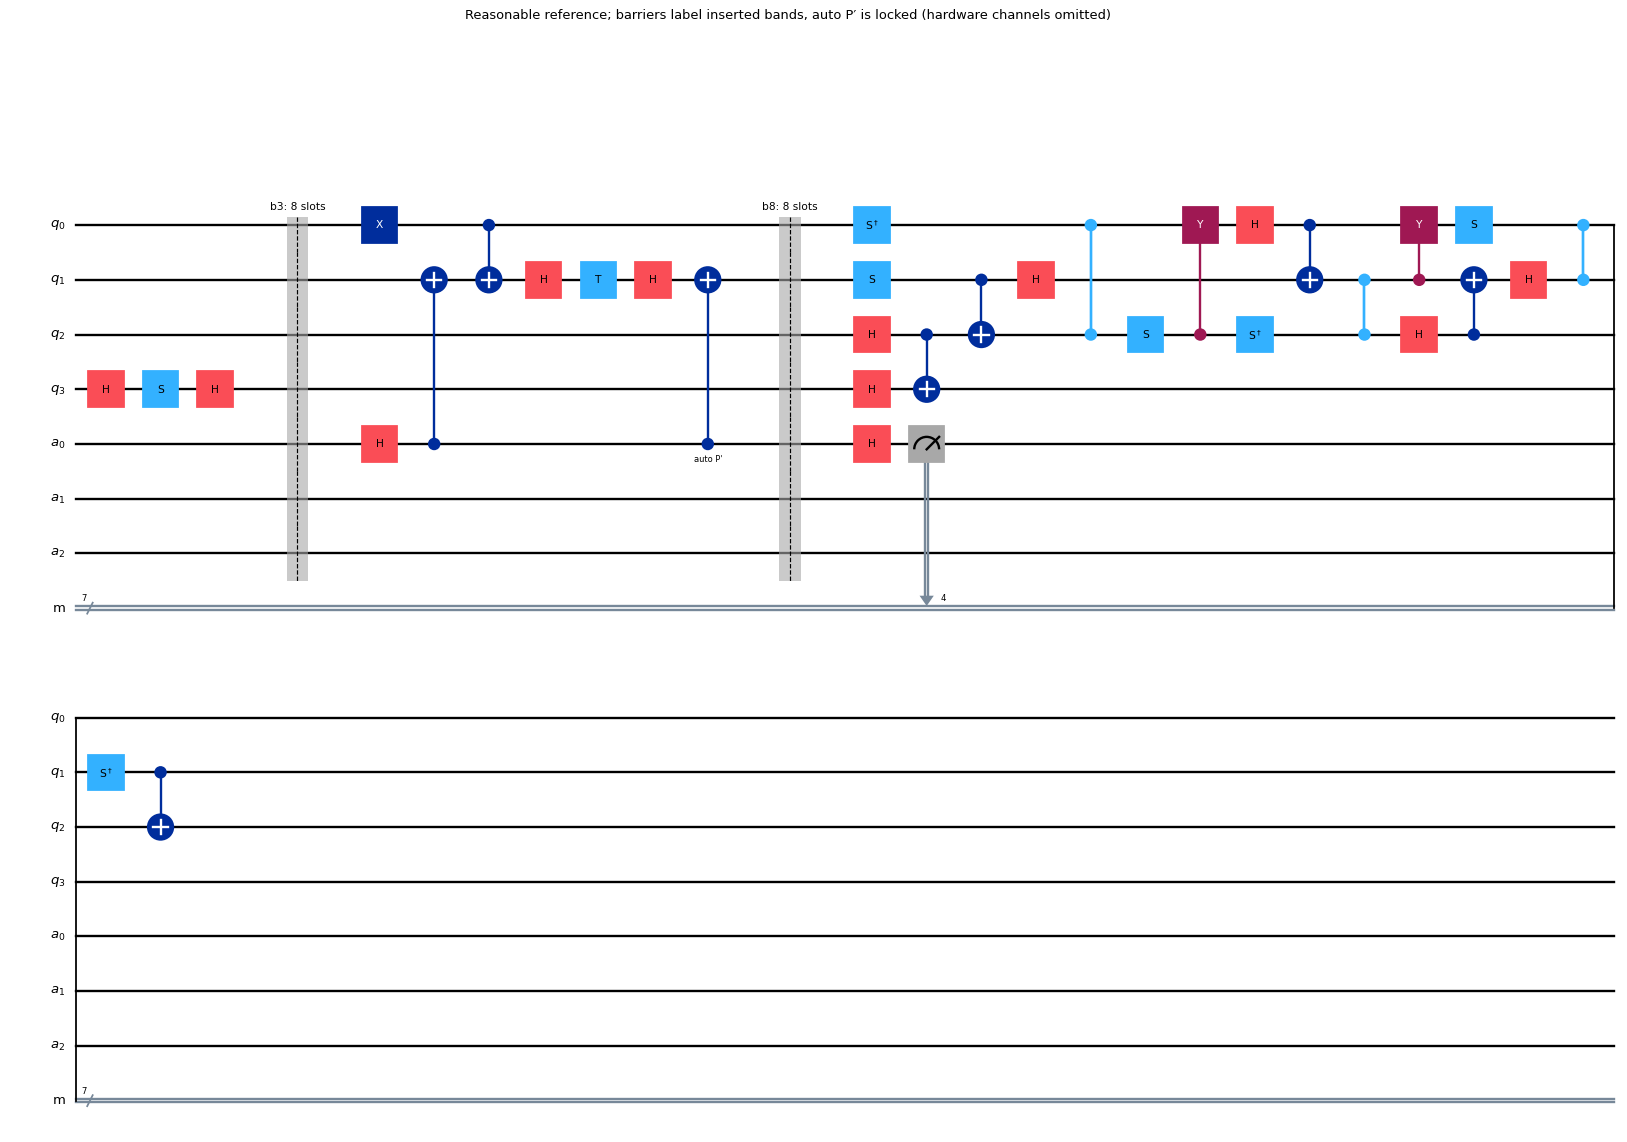

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.390749,1,0.390749,0.56,0,False,False,0,0
everywhere,0.332529,0.637343,0.211935,0.56,0,True,False,3,24
reasonable,0.770041,0.800357,0.616308,0.56,0,True,True,1,2
optimal,0.77056,0.80141,0.617534,0.56,0,True,True,1,2


Data: 4 Fixed helpers: 3 T/Tdg: 1 Payload gates: 30 Depth: 19
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 4, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 90.0}
Inserted editable bands: {"0": 4, "3": 8, "30": 8, "8": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b3s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [4, 1], "location": "auto-0-0", "locked": true}]
Search: custom-t-pauli-search candidates: 891 best opening: IIXI interval: (4, 5) cached search seconds: 126.526
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; statevector ideal; no Paulice


In [18]:
row, STRATEGY_ROWS[8] = lab.main_level(8, CACHE)
SUMMARY.append(row)

<a id="main9"></a>
## 4.9. Main Level 9

Additional T/Tdg barriers narrow valid Pauli support and locations. The same T-capable scorer and custom search are used; compare the stored best-found interval with a reasonable, lower-scoring valid solution.

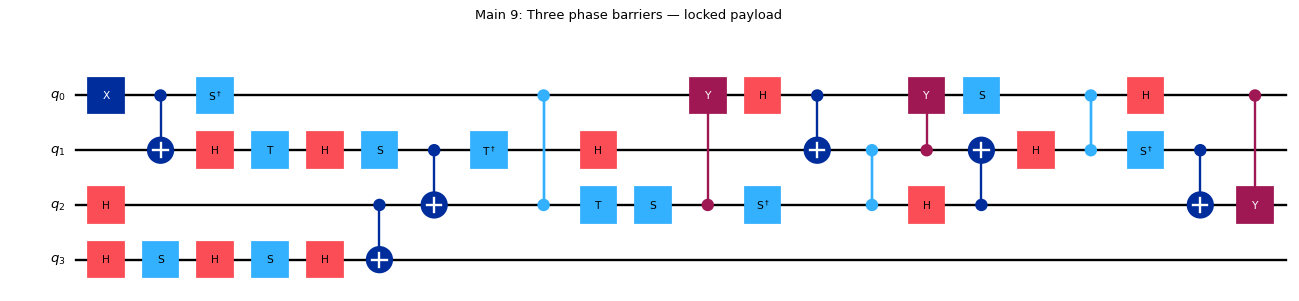

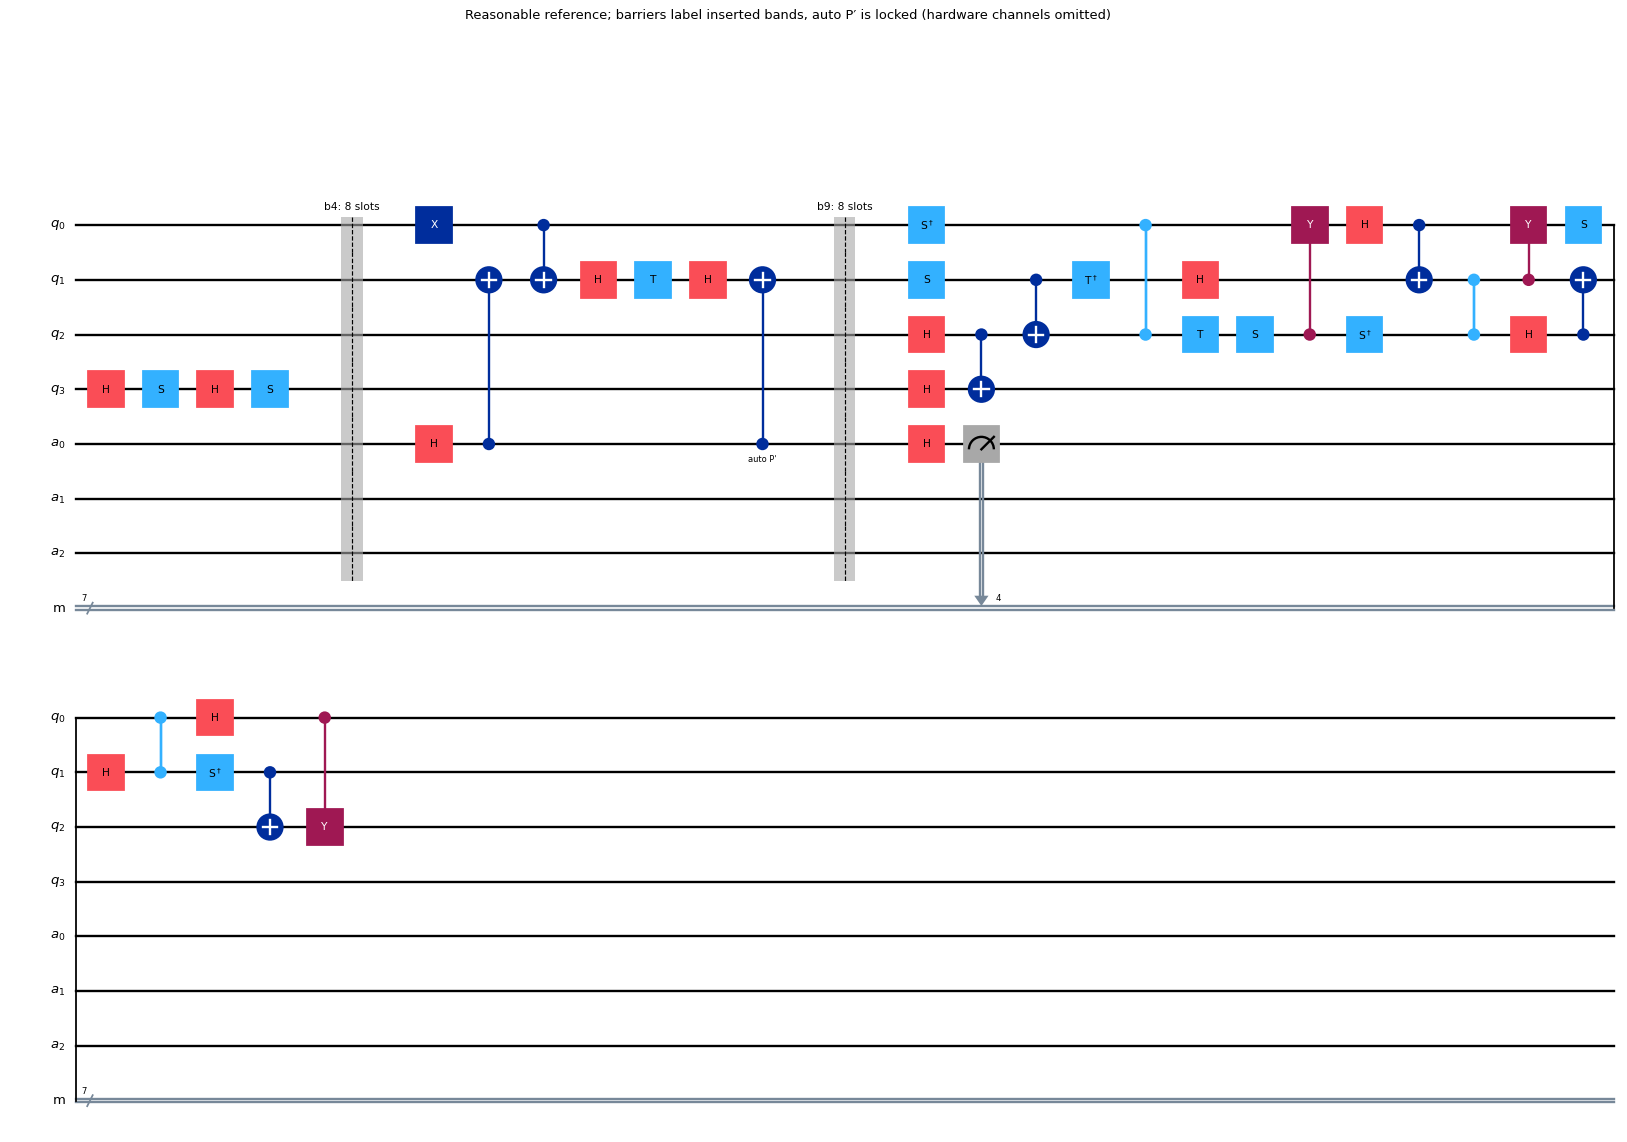

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.381199,1,0.381199,0.55,0,False,False,0,0
everywhere,0.322992,0.632148,0.204179,0.55,0,True,False,3,24
reasonable,0.762885,0.79722,0.608187,0.55,0,True,True,1,2
optimal,0.763399,0.798262,0.609392,0.55,0,True,True,1,2


Data: 4 Fixed helpers: 3 T/Tdg: 3 Payload gates: 35 Depth: 21
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 5, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 92.0}
Inserted editable bands: {"0": 4, "35": 8, "4": 8, "9": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b4s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [4, 1], "location": "auto-0-0", "locked": true}]
Search: custom-t-pauli-search candidates: 699 best opening: IIXI interval: (5, 6) cached search seconds: 70.327
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; statevector ideal; no Paulice


In [19]:
row, STRATEGY_ROWS[9] = lab.main_level(9, CACHE)
SUMMARY.append(row)

<a id="main10"></a>
## 4.10. Main Level 10

The largest T-doped mission remains within the physical-wire bound. All baseline/blanket/reasonable/best-found records are run repeatedly, including the ordinary auto-P′ logic. The best-found label is bounded by the cached search family, not a universal optimizer claim.

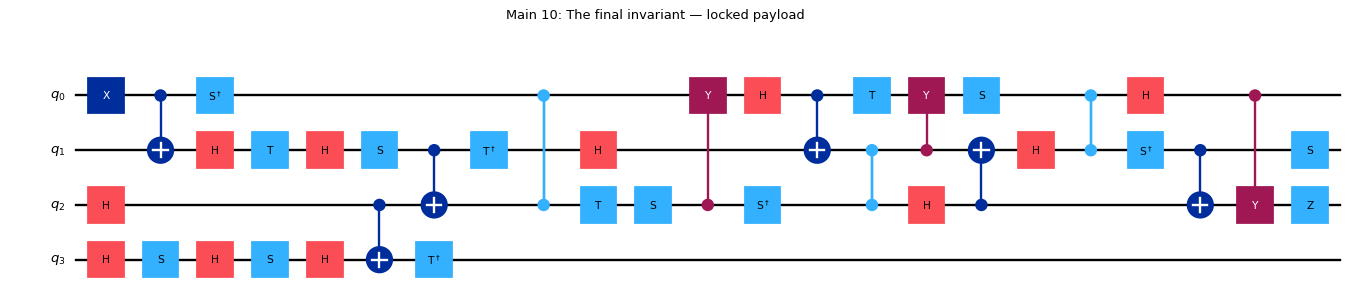

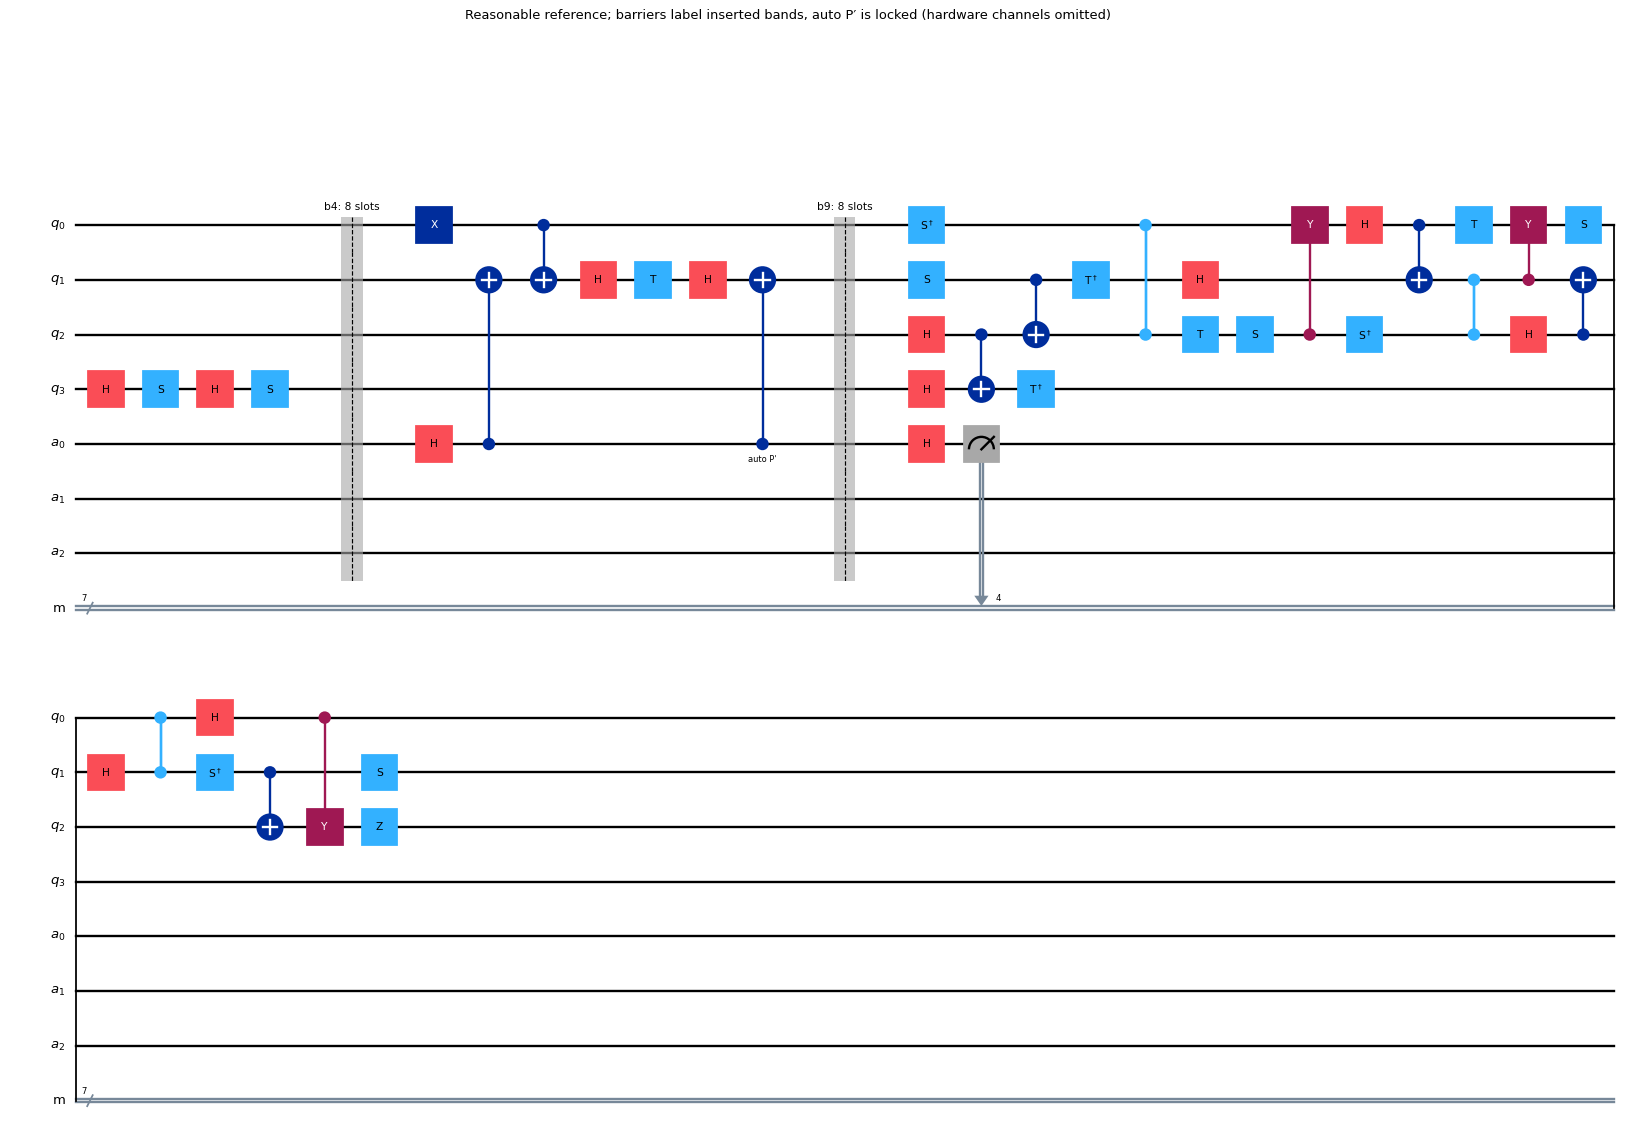

strategy,fidelity,kept,score,target,spread,valid,passed,checkLoops,controlledPaulis
baseline,0.371958,1,0.371958,0.55,0,False,False,0,0
everywhere,0.327538,0.663749,0.217403,0.55,0,True,False,3,21
reasonable,0.755789,0.794262,0.600295,0.55,0,True,True,1,2
optimal,0.756297,0.795294,0.601479,0.55,0,True,True,1,2


Data: 4 Fixed helpers: 3 T/Tdg: 5 Payload gates: 39 Depth: 22
Noise: {"checkStrength": 0.025, "hardware": {"bitFlip": 0.00015, "depolarizing": 0.0002, "enabled": true, "phaseFlip": 0.00015, "relaxationTimeUs": 0.0, "t1Us": 100.0, "t2Us": 200.0}, "hotspotColumn": 5, "qubit": 1, "t1Us": 100.0, "t2Us": 200.0, "timeUs": 94.0}
Inserted editable bands: {"0": 4, "39": 8, "4": 8, "9": 8}
Real dynamic endpoints: [{"ancilla": "a0", "opening": "b4s2", "closing": "auto-0-0", "valid": true}]
Locked auto P′: [{"operator": "cx", "wires": [4, 1], "location": "auto-0-0", "locked": true}]
Search: custom-t-pauli-search candidates: 651 best opening: IIXI interval: (5, 6) cached search seconds: 74.479
Scope: Exact maximum over all nonidentity single-helper Pauli products in the five declared windows. Not a global optimum over arbitrary multi-helper circuits.
Scorer: Aer density_matrix; statevector ideal; no Paulice


In [20]:
row, STRATEGY_ROWS[10] = lab.main_level(10, CACHE)
SUMMARY.append(row)

<a id="cross-level"></a>
## 5. Cross-level analysis

The summary includes every lesson; FS1–5 deliberately have no numeric qualification score. All scored entries below come from fresh evaluator calls. Target position is a descriptive ratio computed from those values, not a calibration change. Fidelity and retained yield are plotted together; check-loop count and controlled-Pauli interaction cost are distinct resources.

The difficulty plot uses width, depth, gate count and T count as structural proxies. It is not a measured human difficulty score. Saved finite-family winners can outperform an easy-to-find reference without proving an unrestricted optimum.

level,data,ancillas,tCount,baseline,everywhere,reasonable,optimal,target,spread,completion,demonstratedFidelity
FS1,1,0,0,—,—,—,—,—,—,Run experiment and correctly answer all three MCQs.,0
FS2,1,method-dependent,0,—,—,—,—,—,—,Try all three methods on a valid authored circuit.,—
FS3,1,1,0,—,—,—,—,—,—,Complete the guided physical check and knowledge questions.,—
FS4,2,1,0,—,—,—,—,—,—,Complete the guided physical check and knowledge questions.,—
FS5,1,1,1,—,—,—,—,—,—,Complete the guided physical check and knowledge questions.,—
FS6,2,1,0,0.494132,0.45698,0.668136,0.686119,0.62,0,"Pass score threshold, review real Paulice and reference comparison.",—
Main1,2,1,0,0.466665,0.435775,0.681383,0.681615,0.6,0,Score target with a valid invariant,—
Main2,3,1,0,0.455944,0.406086,0.672137,0.672365,0.6,0,Score target with a valid invariant,—
Main3,3,2,0,0.445385,0.336067,0.665396,0.665621,0.59,0,Score target with a valid invariant,—
Main4,3,2,0,0.436066,0.331921,0.659251,0.659472,0.59,0,Score target with a valid invariant,—


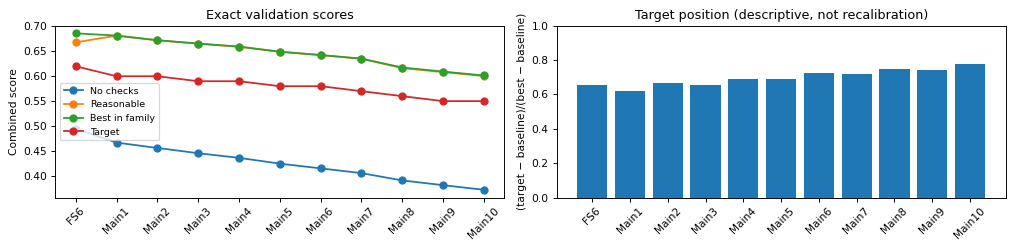

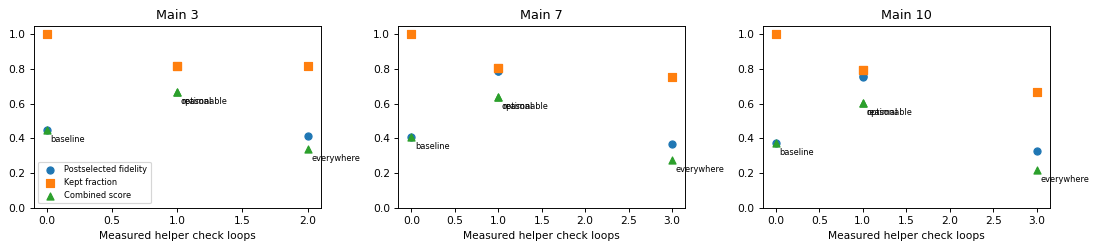

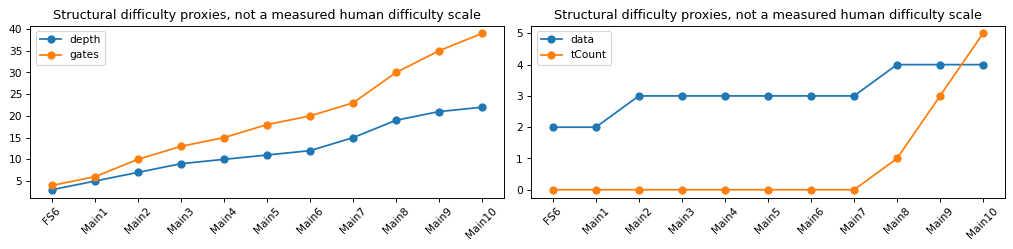

All displayed scored rows will be checked against full-precision reference JSON and the rounded validation document.


In [21]:
DIFFICULTY = lab.cross_level(SUMMARY, STRATEGY_ROWS)
from scripts.run_notebook import validate_manifest
print("All displayed scored rows will be checked against full-precision reference JSON and the rounded validation document.")

<a id="t-validation"></a>
## 6. T-capable scorer validation and timing

Call the existing validation function, rather than copy its comparison physics. It compares the T-capable scorer to the Clifford reference on Clifford workloads, checks an independent small dense-channel evolution, verifies noiseless Z/T retention and rejects X/Y crossings before scoring. Repeated uncached T runs exercise the full physical register. Timings below are actual local measurements, not deployment cold-start guarantees.

In [22]:
from scripts.validate_t_scoring import verify_t_scoring
T_CHECK = verify_t_scoring()
table(T_CHECK["cliffordAgreement"])
table([dict(smallCliffordDensityDifference=T_CHECK["smallCliffordDensityDifference"])])
table([dict(level=row["level"], physicalQubits=row["physicalQubits"], engine=row["engine"],
            noiselessZ=row["noiselessZ"], invalidXYRejected=row["invalidXYRejected"],
            smallTDensityDifference=row["smallTDensityDifference"],
            runSeconds=row["coldRunSeconds"], scoreSpread=row["scoreSpread"])
       for row in T_CHECK["tLevels"]])

level,maxMetricDifference
1,2.22045e-16
2,2.22045e-16
3,5.55112e-16
4,4.44089e-16
5,5.55112e-16
6,5.55112e-16
7,7.77156e-16


smallCliffordDensityDifference
2.77556e-16


level,physicalQubits,engine,noiselessZ,invalidXYRejected,smallTDensityDifference,runSeconds,scoreSpread
8,7,Aer density_matrix; statevector ideal; custom I/Z-at-T placement search,"{""fidelity"": 1.0, ""retention"": 1.0, ""score"": 1.0}",True,2.22045e-16,"[0.22506769999745302, 0.3591708999883849, 0.2447251999983564]",0
9,7,Aer density_matrix; statevector ideal; custom I/Z-at-T placement search,"{""fidelity"": 1.0, ""retention"": 1.0, ""score"": 1.0}",True,2.22045e-16,"[0.3230211999907624, 0.2831116000015754, 0.32488280002144165]",0
10,7,Aer density_matrix; statevector ideal; custom I/Z-at-T placement search,"{""fidelity"": 1.0, ""retention"": 1.0, ""score"": 1.0}",True,2.22045e-16,"[0.3350998999958392, 0.3322939000208862, 0.2666987999982666]",0


<a id="reproducibility"></a>
## 7. Reproducibility and computed verification record

The runner executes in a real kernel, fails on any cell error, and independently compares the summary with `backend/missions/references.json`, `docs/CAPSTONE_DIFFICULTY_VERIFICATION.json` and `docs/LEVEL_VALIDATION.md`. Exact-score comparison allows the existing floating-point epsilon in addition to the stored spread; rounded human tables allow their documented rounding. It rejects missing/unexecuted cells and stale source/cache fingerprints. `python scripts/run_notebook.py --check-saved` validates the saved artifact without executing it again.

Rebuild expensive searches only when needed: `python scripts/cache_level_searches.py`. Re-run all ordinary gameplay validation with `python scripts/validate_all_levels.py`. Full search time and interactive analysis time are reported separately; importing cached winners is not presented as a fresh search. Neither command recalibrates targets. Clean environment installation uses only `notebooks/requirements.txt`; Jupyter/drawing tools stay outside the Vercel bundle because `notebooks/` and `scripts/` are already excluded.

In [23]:
PACKAGE_NAMES=["qiskit","qiskit-aer","qiskit-paulice","numpy","scipy","matplotlib","pylatexenc",
               "nbformat","nbclient","nbconvert","ipykernel"]
table([dict(package=name, version=version(name)) for name in PACKAGE_NAMES])
RUNTIME = time.perf_counter()-START
print("Python:",platform.python_version(),"Seed:",SEED,"Sampled diagnostic shots:",SHOTS)
print("Actual analysis seconds (kernel startup excluded):",round(RUNTIME,3))
print("One-time cached search seconds:",round(CACHE["seconds"],3))
print("Execution completed UTC:",datetime.now(timezone.utc).isoformat())
print("No absolute filesystem paths or user names are included in the displayed results.")

package,version
qiskit,2.5.2
qiskit-aer,0.17.2
qiskit-paulice,0.2.1
numpy,2.2.6
scipy,1.15.3
matplotlib,3.10.9
pylatexenc,2.11
nbformat,5.10.4
nbclient,0.10.2
nbconvert,7.16.6


Python: 3.10.10 Seed: 2026 Sampled diagnostic shots: 1024
Actual analysis seconds (kernel startup excluded): 25.962
One-time cached search seconds: 390.015
Execution completed UTC: 2026-10-16T11:52:12.471147+00:00
No absolute filesystem paths or user names are included in the displayed results.


In [24]:
MANIFEST=dict(schemaVersion=1, summary=SUMMARY, seed=SEED, shots=SHOTS,
              runtimeSeconds=RUNTIME, cachedSearchSeconds=CACHE["seconds"],
              tValidationPassed=all(row["invalidXYRejected"] for row in T_CHECK["tLevels"]),
              packages={name:version(name) for name in PACKAGE_NAMES},
              inputs=analysis_inputs())
assert validate_manifest(MANIFEST)==len(SUMMARY)
display(JSON(MANIFEST,expanded=False))

<IPython.core.display.JSON object>